# 第1回　線形代数 — 機械学習の計算はすべて行列で書ける

| 項目 | 内容 |
| --- | --- |
| 教科書の範囲 | 第 0 章 線形代数　0.1 逆行列 / 0.2 行列式 / 0.3 一次独立性 / 0.4 ベクトル空間とその次元 / 0.5 固有値と固有ベクトル / 0.6 正規直交基底と直交行列 / 0.7 対称行列の対角化 |
| 命題 | 命題 1 〜 命題 10 |
| この回の到達点 | ① 連立方程式・階数・逆行列を掃き出し法で説明できる<br>② 固有値分解と特異値分解を式と数値の両方で検算できる<br>③ 非負定値性の 3 つの同値条件を言える |
| 後の回とのつながり | 第 2 回 $\hat\beta=(X^TX)^{-1}X^Ty$ の存在条件 ／ 第 6 回 Ridge の $X^TX+N\lambda I$ が正則になる理由 ／ 第 13 回 主成分分析（共分散行列の対角化） |

第 0 章には章末問題はなく、今後必ず活用することになる
命題の内容を、式・数値例・図で確認する。数値例は一般的な証明の代わりにはならない。

---

**<font color="#E8710A">［要点］この回で押さえる 3 つの等式</font>**

$$\operatorname{rank}(A)+\dim(\ker A)=n,\qquad
A=P\Lambda P^{T},\qquad
A\succeq 0 \iff A=B^{T}B$$
1 番目は「情報量」の測定、2 番目は実対称行列を対象とし、「行列を方向と伸縮率に分解する」操作、
3 番目は「二乗和で書ける行列は非負定値」という、第 6 回の正則化まで有効になる。

---

[学習記録の概要・検証結果・参考資料](../README.md)


## 0. インポートと初期設定

In [1]:
#使うライブラリをまとめて読み込む
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

#グラフで日本語を使えるようにする（環境にある日本語フォントを選ぶ）
from matplotlib import font_manager
font_candidates = ['Noto Sans CJK JP', 'Noto Sans JP', 'IPAexGothic',
                   'IPAGothic', 'Hiragino Sans', 'Yu Gothic', 'Meiryo']
installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = [name for name in font_candidates if name in installed_fonts] + ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
#日本語が四角に化けるときは次の行を実行してから、ランタイムを再起動する
#!apt-get -y install fonts-ipafont-gothic

#グラフの見た目をそろえる
plt.rcParams['figure.figsize'] = (7.2, 4.4)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25

#色設定
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
MAGENTA, GREEN, VIOLET, RED = '#e87ba4', '#008300', '#4a3aa7', '#e34948'
PAL = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=PAL)

#乱数。教科書の randn(n) と同じ書き方ができるようにしておく
rng = np.random.default_rng(2026)
def randn(*shape):
    return rng.standard_normal(shape)

### 記号の約束

今後は行列を大文字、ベクトルを小文字で書き、$x_i$ は<u><font color="#E8710A">行ベクトル</font></u>（1 件の観測）を表す。
NumPy の配列と対応させると次のようになる。

| 数学の記号 | 意味 | NumPy での形 | 注意 |
| --- | --- | --- | --- |
| $N$ | 観測（サンプル）の個数 | `X.shape[0]` | 本書は $n$ ではなく $N$ を使う |
| $p$ | 説明変数の個数 | `X.shape[1]` | 切片を含めるときは $p+1$ 列 |
| $X\in\mathbb{R}^{N\times p}$ | 計画行列（1 行 = 1 観測） | `(N, p)` | 行と列を取り違えるとすべて壊れる |
| $x_i$ | 第 $i$ 観測（行ベクトル） | `X[i]` → 形 `(p,)` | `X[i:i+1]` なら `(1, p)` |
| $X_{\cdot j}$ | 第 $j$ 特徴量（列） | `X[:, j]` → 形 `(N,)` |  |
| $\beta\in\mathbb{R}^{p}$ | 係数ベクトル | `(p,)` | `(p, 1)` にすると結果が 2 次元になる |
| $A^{T}$ | 転置 | `A.T` |  |
| $A^{-1}$ | 逆行列 | `np.linalg.inv(A)` | 実務では `solve` を使う |
| $\Vert z\Vert $ | ユークリッドノルム $\sqrt{\sum z_i^2}$ | `np.linalg.norm(z)` |  |

---

**<font color="#D93025">［注意］1 次元配列と列ベクトルは別物</font>**

$\beta\in\mathbb{R}^{p}$ に対応する NumPy の形は `(p,)` であって `(p, 1)` ではない。
`X @ beta` は前者なら形 `(N,)` を返すが、後者なら `(N, 1)` を返す。
後で `y - X @ beta` を計算したとき `y` が `(N,)` だと
ブロードキャストが起きて `(N, N)` という巨大な行列が黙って生成される。
誤差が急に大きくなったら、まず `.shape` を並べて印字する。

---

---
## 1. 逆行列 — 掃き出し法がすべての出発点（教科書 0.1）

### 1.1 3 つの基本変形

連立方程式 $Ax=b$ を解くとき、紙の上でやっているのは次の 3 つの操作だけである。
$A$ の横に $b$ を並べた<u><font color="#E8710A">拡大係数行列</font></u> $[A\,|\,b]\in\mathbb{R}^{m\times(n+1)}$ に対して、

1. ある行全体を非ゼロ定数で割る（ルール 1）

2. ある 2 行を入れ替える（ルール 2）

3. ある行の何倍かを他の行に加える（ルール 3）

この 3 操作で $A$ が $B$ に変形できることを $A\sim B$ と書く。重要なのは、
<u><font color="#E8710A">3 つの操作はいずれも解の集合を変えない</font></u>という点である。ルール 1 は方程式の両辺を定数倍する操作、
ルール 3 は 2 つの方程式を足し合わせる操作で、どちらも同値変形になっている。

### 1.2 標準形と階数

基本変形を尽くすと、行列は次の条件を満たす<u><font color="#E8710A">標準形</font></u>にたどり着く。

---

**<font color="#C08A00">［命題］標準形の条件（教科書 p.2）</font>**

1. 0 の行ベクトルは、最下段にある
2. 0 でない行ベクトルの主成分（最初の非ゼロ成分）は 1
3. 各行の主成分は、下の行ほど右にある
4. 主成分を含む列の、主成分以外の成分は 0

標準形は一意に定まり、その主成分の個数を **階数** $\operatorname{rank}(A)$ という。
定義から $\operatorname{rank}(A)\le\min\{m,n\}$。

---

$A$ が正方で標準形が単位行列になるとき、$A$ は<u><font color="#E8710A">正則</font></u>であるという。
$[A\,|\,I]\sim[I\,|\,B]$ が得られたとき $A^{-1}=B$ である。理由は、
基本変形は「左から正則行列 $P$ を掛ける」ことに等しく、
$[A\,|\,I]\sim[I\,|\,B]$ は $PA=I$ かつ $PI=B$、すなわち $P=B$ と $BA=I$ を同時に主張しているからである。

### 1.3 逆行列を「作らない」で解く

$Ax=b$ を解きたいだけなら $A^{-1}$ は要らない。$[A\,|\,b]\sim[I\,|\,x^{*}]$ とすれば
$x^{*}$ が直接得られる。数値計算では $A^{-1}$ を経由するほど誤差が増えるので、
<u><font color="#E8710A">求めたい量を直接計算する</font></u>のが原則である。

In [2]:
#掃き出し法（ガウス・ジョルダン法）を、教科書のルール 1・2・3 の順に書き下す
def sweep(M, verbose=False):
    """行列 M を標準形に変形し、(標準形, 階数) を返す。M 自身は変更しない。"""
    A = M.astype(float).copy()
    rows, cols = A.shape
    r = 0                                   # いま主成分を置きたい行
    for c in range(cols):
        if r >= rows:
            break
        #ルール2: 第 c 列で絶対値最大の行を選んで入れ替える（部分ピボット選択）
        piv = r + int(np.argmax(np.abs(A[r:, c])))
        if abs(A[piv, c]) < 1e-12:          # この列に主成分は立たない
            continue
        A[[r, piv]] = A[[piv, r]]
        #ルール1: 主成分を 1 にする
        A[r] = A[r] / A[r, c]
        #ルール3: 同じ列の他の行をすべて 0 にする
        for i in range(rows):
            if i != r:
                A[i] = A[i] - A[i, c] * A[r]
        if verbose:
            print(f"第{c}列を処理 → 主成分を第{r}行に配置")
            print(np.round(A, 3), "\n")
        r += 1
    return A, r                              # r がそのまま階数になる

A = np.array([[1., 2., 1.], [2., 3., 1.], [1., 2., 2.]])
std, rank_augmented = sweep(np.hstack([A, np.eye(3)]))   # [A | I] を掃き出す
_, rank = sweep(A)                            # 係数行列自体の階数を確認
Ainv = std[:, 3:]                              # 右半分が A^{-1}

print("階数 :", rank)
print("掃き出しで得た A^{-1} =\n", np.round(Ainv, 6))
print("np.linalg.inv との一致 :", np.allclose(Ainv, np.linalg.inv(A)))
print("A @ A^{-1} = I の検算  :", np.allclose(A @ Ainv, np.eye(3)))

階数 : 3
掃き出しで得た A^{-1} =
 [[-4.  2.  1.]
 [ 3. -1. -1.]
 [-1.  0.  1.]]
np.linalg.inv との一致 : True
A @ A^{-1} = I の検算  : True


| 書き方 | していること | 読みどころ |
| --- | --- | --- |
| `A.astype(float).copy()` | 入力を壊さない | `copy()` を忘れると呼び出し元の配列が書き換わる。整数配列のままだと割り算が切り捨てられる |
| `piv = argmax(abs(...))` | ルール 2 | 数学的には非ゼロならどれでもよいが、絶対値が最大の行を選ぶと丸め誤差が小さい（部分ピボット選択） |
| `abs(A[piv,c]) < 1e-12` | 主成分が立たない列 | 浮動小数では厳密な 0 にならない。`== 0` で判定してはいけない |
| `A[[r, piv]] = A[[piv, r]]` | 2 行の入れ替え | 右辺が先に評価されるので、この 1 行で交換できる |
| `A[i] -= A[i,c] * A[r]` | ルール 3 | `i != r` にしているので主成分行自身は引かない。全行にすると主成分が 0 になる |
| `return A, r` | 階数 | 主成分を置いた回数 `r` がそのまま $\operatorname{rank}(A)$ |

---

**<font color="#0F9D58">［読み方］出力の読み方</font>**

$\operatorname{rank}=3$ は $3\times3$ 行列の列数と等しいので $A$ は正則。`np.allclose` は
丸め誤差を許して全要素を比較する関数で、`==` による完全一致より浮動小数の検算に向く。
比較している左右がそれぞれ数学のどの式なのかを、毎回言葉で説明できるようにしておく。

`sweep`が返すのは引数全体の階数である。拡大行列`[A | I]`の階数と`A`の階数を混同しない。上の例では`A`自体の階数が3であることも確認している。

---

### 1.4 階数が足りないとどうなるか

列が重複している行列では、掃き出しの途中で 0 の行が現れる。

In [3]:
B = np.array([[1., 2.], [2., 4.], [3., 6.]])   # 第2列は第1列の2倍
std_B, rank_B = sweep(B)
print("B の標準形 =\n", np.round(std_B, 3))
print(f"列数 = {B.shape[1]}, rank = {rank_B}  → 列は2本あるが独立な情報は1本")

S = np.array([[1., 2.], [2., 4.]])             # 正則でない正方行列
try:
    np.linalg.inv(S)
except np.linalg.LinAlgError as e:
    print("\ninv(S) は失敗 :", e)
print("lstsq ならノルム最小の最小二乗解を返す :",
      np.round(np.linalg.lstsq(S, np.array([1., 2.]), rcond=None)[0], 4))

B の標準形 =
 [[1. 2.]
 [0. 0.]
 [0. 0.]]
列数 = 2, rank = 1  → 列は2本あるが独立な情報は1本

inv(S) は失敗 : Singular matrix
lstsq ならノルム最小の最小二乗解を返す : [0.2 0.4]


---
## 2. 行列式 — 「体積の倍率」として読む（教科書 0.2）

### 2.1 定義は掃き出しの逆再生

本書の行列式の定義は公式を暗記させない。標準形から<u><font color="#E8710A">逆向きに</font></u>手順を戻し、
そのたびに値を更新していく。

---

**<font color="#C08A00">［命題］行列式の定義（教科書 p.3）</font>**

標準形が単位行列でないとき（$A$ が正則でないとき）$\det(A)=0$ と定める。

単位行列に対し $\det(I)=1$ と定め、標準形から $A$ へ戻る操作に応じて次のように更新する。

1. ある行全体を非ゼロ定数 $\alpha$ 倍するとき、$\det(A)$ を $\alpha$ 倍する
2. ある 2 行を入れ替えるとき、$\det(A)$ を $-1$ 倍する
3. ある行の $\beta$ 倍を他の行から引くとき、$\det(A)$ の値は変えない

---

---

**<font color="#C08A00">［命題］命題 1（教科書 p.3）</font>**

正方行列 $A$ について
$$A\ \text{が正則}\iff \operatorname{rank}(A)=n \iff \det(A)\neq0$$

---

$2\times2$ の場合、$a\neq0$ なら第 1 行の $c/a$ 倍を第 2 行から引いて

$$\begin{vmatrix} a & b \\ c & d\end{vmatrix}
=\begin{vmatrix} a & b \\ 0 & d-\dfrac{bc}{a}\end{vmatrix}=ad-bc$$

が出る。$a=0$ のときも行を入れ替えて符号を付ければ $ad-bc$ になる。

### 2.2 教科書にない図で意味をつかむ

行列式の値そのものは公式で出るが、<u><font color="#E8710A">なぜ 0 だとまずいのか</font></u>は図で見るのが早い。
$2\times2$ 行列 $A$ は、単位正方形 $[0,1]^2$ を平行四辺形へ写す。その平行四辺形の
<u><font color="#E8710A">符号つき面積が $\det(A)$</font></u>である。$\det(A)=0$ とは面積が潰れて線分になった状態、
つまり 2 本の列ベクトルが一次従属（平行、または零ベクトルを含む）になった状態を指す。

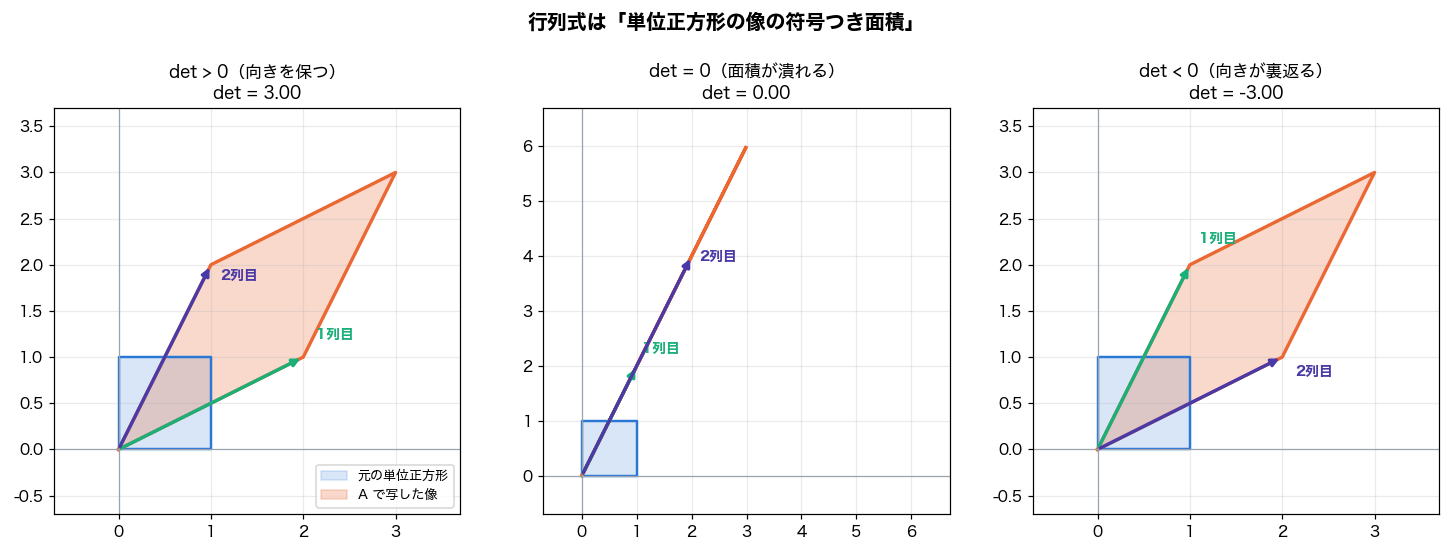

In [4]:
def draw_unit_square_map(ax, A, title):
    """単位正方形が A によってどう写るかを描く"""
    sq = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]], float).T   # 2 x 5
    img = A @ sq
    ax.fill(sq[0], sq[1], color=BLUE, alpha=0.18, label="元の単位正方形")
    ax.plot(sq[0], sq[1], color=BLUE, lw=1.6)
    ax.fill(img[0], img[1], color=ORANGE, alpha=0.25, label="A で写した像")
    ax.plot(img[0], img[1], color=ORANGE, lw=2.2)
    for col, c, name, dy in zip(A.T, [AQUA, VIOLET], ["1列目", "2列目"], [0.16, -0.24]):
        ax.annotate("", xy=col, xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", lw=2.2, color=c))
        ax.text(col[0]*1.04 + 0.06, col[1]*1.04 + dy, name, color=c,
                fontweight="bold", fontsize=9)
    ax.axhline(0, color="#98a4b0", lw=0.8); ax.axvline(0, color="#98a4b0", lw=0.8)
    ax.set_aspect("equal")
    #像と列ベクトル全体が見えるように表示範囲を決める
    lo = min(float(sq.min()), float(img.min()), float(A.min()), 0.0) - 0.7
    hi = max(float(sq.max()), float(img.max()), float(A.max())) + 0.7
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_title(f"{title}\ndet = {np.linalg.det(A):.2f}", fontsize=11)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8))
draw_unit_square_map(axes[0], np.array([[2., 1.], [1., 2.]]), "det > 0（向きを保つ）")
draw_unit_square_map(axes[1], np.array([[1., 2.], [2., 4.]]), "det = 0（面積が潰れる）")
draw_unit_square_map(axes[2], np.array([[1., 2.], [2., 1.]]), "det < 0（向きが裏返る）")
axes[0].legend(loc="lower right", fontsize=8.5)
fig.suptitle("行列式は「単位正方形の像の符号つき面積」", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.92]); plt.show()

---

**<font color="#E8710A">［要点］図の読み取り</font>**

中央の $A=\begin{bmatrix}1&2\\2&4\end{bmatrix}$ では 2 本の列ベクトル（緑と紫）が
完全に同じ向きを向いていて、像が線分に潰れている。
$\det(A)=0$、$\operatorname{rank}(A)=1$、「$A^{-1}$ が存在しない」の 3 つが
同じ事態を指しているというのはこの意味である。第 2 回で $X^TX$ が正則でない状況
（$N<p+1$、または $X$ の 2 列が等しい）を扱うが、そこで起きているのはこの「潰れ」である。

---

### 2.3 命題 2 と、実装での確かめ

---

**<font color="#C08A00">［命題］命題 2（教科書 p.3）</font>**

正方行列 $A,B$ について $\det(AB)=\det(A)\det(B)$ および $\det(A^{T})=\det(A)$ が成立する。

---

$\det(AB)=\det(A)\det(B)$ は、基本変形が「基本行列を左から掛ける操作」であり、
$\det$ がその積に対して掛け算的にふるまうことから従う。この性質は
$\det(A^{-1})=1/\det(A)$、$\det(X^TX)=\det(X)^2$（$X$ が正方のとき）など、後で何度も使う。

In [5]:
A = np.array([[2., -1., 5.], [0., 1., 1.], [1., 0., 3.]])
B = np.array([[1., 2., 1.], [2., 3., 1.], [1., 2., 2.]])

print(f"det(A)        = {np.linalg.det(A): .6f}")
print(f"det(B)        = {np.linalg.det(B): .6f}")
print(f"det(A)·det(B) = {np.linalg.det(A)*np.linalg.det(B): .6f}")
print(f"det(A @ B)    = {np.linalg.det(A @ B): .6f}   ← 命題2の前半")
print(f"det(A.T)      = {np.linalg.det(A.T): .6f}   ← 命題2の後半")

#Vandermonde 行列（例7）: a が相異なれば det ≠ 0 → 多項式回帰の設計行列が正則になる根拠
a = np.array([1., 2., 3., 5.])
V = np.vander(a, increasing=True)
prod = np.prod([a[j]-a[i] for i in range(4) for j in range(i+1, 4)])
print("\nVandermonde 行列 =\n", V)
print(f"det = {np.linalg.det(V):.4f}   Π(a_j - a_i) = {prod:.4f}")

det(A)        =  0.000000
det(B)        = -1.000000
det(A)·det(B) = -0.000000
det(A @ B)    =  0.000000   ← 命題2の前半
det(A.T)      =  0.000000   ← 命題2の後半

Vandermonde 行列 =
 [[  1.   1.   1.   1.]
 [  1.   2.   4.   8.]
 [  1.   3.   9.  27.]
 [  1.   5.  25. 125.]]
det = 48.0000   Π(a_j - a_i) = 48.0000


---

**<font color="#1A73E8">［補足］Vandermonde 行列がここに出てくる理由</font>**

$V=[a_i^{\,j-1}]$ の行列式は $\prod_{i<j}(a_j-a_i)$ に等しい。したがって
$a_1,\dots,a_n$ が相異なれば $\det(V)\neq0$。これは第 7 回（多項式回帰）で
「$x_1,\dots,x_N$ の中に異なる値が $p+1$ 個以上あれば $X^TX$ は正則」と述べるときの
根拠そのものである（教科書 p.129）。

---

---
## 3. 一次独立性・ベクトル空間・次元（教科書 0.3, 0.4）

### 3.1 一次独立とは「情報が重なっていない」こと

$a_1,\dots,a_n\in\mathbb{R}^m$ について $\sum_i x_ia_i=0 \Rightarrow x_1=\cdots=x_n=0$
が成り立つとき一次独立という。$A=[a_1,\dots,a_n]$ と並べれば、これは
<u><font color="#E8710A">斉次方程式 $Ax=0$ の解が $x=0$ のみ</font></u>ということである。基本変形は解集合を変えないので、
$A\sim B$ なら $A$ の列の独立性と $B$ の列の独立性は一致する。
だから<u><font color="#E8710A">階数 = 一次独立な列ベクトルの最大数</font></u>になる。

---

**<font color="#C08A00">［命題］命題 3（教科書 p.6）</font>**

$A\in\mathbb{R}^{m\times n},\ B\in\mathbb{R}^{n\times r}$ について
$$\operatorname{rank}(AB)\le\min\{\operatorname{rank}(A),\operatorname{rank}(B)\},\qquad
\operatorname{rank}(A^{T})=\operatorname{rank}(A)$$

---

### 3.2 命題 4 — 階数・退化次数定理

---

**<font color="#C08A00">［命題］命題 4（教科書 p.7）</font>**

$A\in\mathbb{R}^{m\times n}$ による線形写像 $\mathbb{R}^n\to\mathbb{R}^m$ を考える。
その**像** $\{Ax\mid x\in\mathbb{R}^n\}$ と**核** $\{x\in\mathbb{R}^n\mid Ax=0\}$ は
それぞれ $\mathbb{R}^m,\mathbb{R}^n$ の部分空間であって
$$\dim(\text{像})+\dim(\text{核})=n,\qquad \dim(\text{像})=\operatorname{rank}(A)$$

---

この等式の読み方はこうである。入力側全体を $\mathbb{R}^n$ としているので $n$ 本の自由度があり、$A$ を通すと
$\operatorname{rank}(A)$ 本だけが出力に残り、残りの $n-\operatorname{rank}(A)$ 本は 0 に潰れる。
<u><font color="#E8710A">潰れた分が核</font></u>である。第 2 回で $\hat\beta$ が一意に決まらない状況、
第 6 回で $\lambda>0$ を足して正則にする話は、どちらもこの勘定に帰着する。

定義域を部分空間 $V$ に制限するときは、右辺を $\dim V$ とし、像と核も制限写像に対して考える。

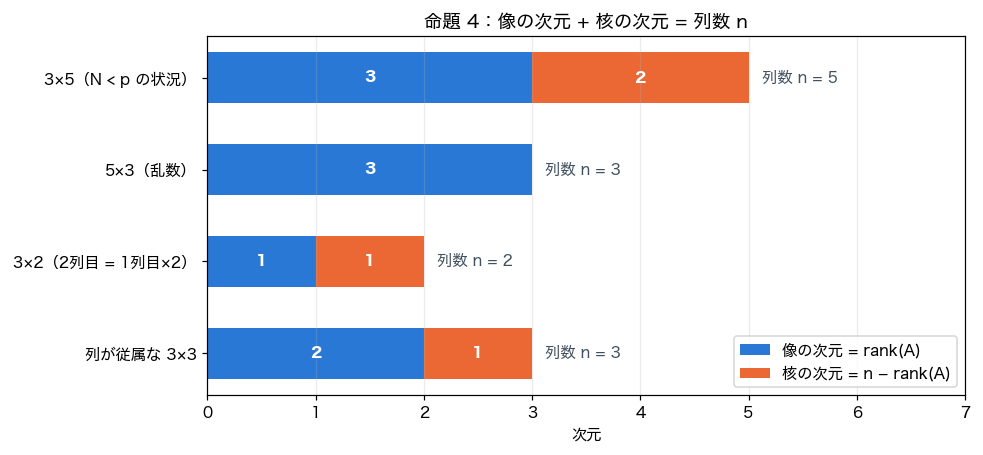

列が従属な 3×3                rank=2  nullity=1  和=3 = n=3
3×2（2列目 = 1列目×2）         rank=1  nullity=1  和=2 = n=2
5×3（乱数）                  rank=3  nullity=0  和=3 = n=3
3×5（N < p の状況）           rank=3  nullity=2  和=5 = n=5


In [6]:
def rank_nullity(A, name):
    n = A.shape[1]
    r = np.linalg.matrix_rank(A)
    return dict(name=name, n=n, rank=r, nullity=n - r)

rg0 = np.random.default_rng(0)
mats = [
    (np.array([[2., 0., -2.], [3., -1., -1.], [1., 1., -3.]]), "列が従属な 3×3"),
    (np.array([[1., 2.], [2., 4.], [3., 6.]]),                 "3×2（2列目 = 1列目×2）"),
    (rg0.standard_normal((5, 3)),                              "5×3（乱数）"),
    (rg0.standard_normal((3, 5)),                              "3×5（N < p の状況）"),
]
reps = [rank_nullity(A, nm) for A, nm in mats]

fig, ax = plt.subplots(figsize=(9.0, 4.2))
ypos = np.arange(len(reps))
ax.barh(ypos, [r["rank"] for r in reps], color=BLUE, height=0.55,
        label="像の次元 = rank(A)")
ax.barh(ypos, [r["nullity"] for r in reps], left=[r["rank"] for r in reps],
        color=ORANGE, height=0.55, label="核の次元 = n − rank(A)")
for i, r in enumerate(reps):
    ax.text(r["n"] + 0.12, i, f'列数 n = {r["n"]}', va="center",
            color="#41505e", fontsize=10)
    ax.text(r["rank"]/2, i, str(r["rank"]), va="center", ha="center",
            color="white", fontweight="bold")
    if r["nullity"]:
        ax.text(r["rank"] + r["nullity"]/2, i, str(r["nullity"]), va="center",
                ha="center", color="white", fontweight="bold")
ax.set_yticks(ypos); ax.set_yticklabels([r["name"] for r in reps])
ax.set_xlim(0, 7.0); ax.set_xlabel("次元")
ax.set_title("命題 4：像の次元 + 核の次元 = 列数 n")
ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

for r in reps:
    print(f'{r["name"]:24s} rank={r["rank"]}  nullity={r["nullity"]}  '
          f'和={r["rank"]+r["nullity"]} = n={r["n"]}')

---

**<font color="#E8710A">［要点］最下段が第 2 回の予告</font>**

$3\times5$ の行列（$N=3$ 観測に対し $p=5$ 変数）は $\operatorname{rank}=3$ に対して核が 2 次元ある。
つまり $X\beta$ を同じ値に保ったまま $\beta$ を 2 方向に自由に動かせる。
これが「$N<p+1$ のとき $X^TX$ が逆行列をもたない」（教科書 p.19、問題 5）の中身である。

---

---
## 4. 固有値と固有ベクトル（教科書 0.5）

### 4.1 定義と、det を使う導出

$A\in\mathbb{R}^{n\times n}$、$\lambda\in\mathbb{C}$、$x\in\mathbb{C}^n\setminus\{0\}$ に対し $Ax=\lambda x$ が成り立つとき、
$\lambda$ を固有値、$x$ を固有ベクトルという。$Ax=\lambda x$ は $(A-\lambda I)x=0$ と同値だから、

$$x\neq0\ \text{なる解が存在} \iff A-\lambda I\ \text{が正則でない}
\iff \det(A-\lambda I)=0$$

という同値の連鎖が得られる。<u><font color="#E8710A">固有多項式は命題 1 の言い換えにすぎない</font></u>。

---

**<font color="#C08A00">［命題］命題 5・命題 6（教科書 p.9）</font>**

**命題 5**　$\lambda$ が $A$ の固有値 $\iff \det(A-\lambda I)=0$。

**命題 6**　実固有値 $\lambda$ の固有空間 $V_\lambda=\{x\in\mathbb{R}^n\mid Ax=\lambda x\}$ は
$\mathbb{R}^n$ の部分空間である。複素固有値を扱う場合は $\mathbb{C}^n$ 上の固有空間を考える。

---

固有空間が部分空間だという事実は地味に効く。$Ax=\lambda x,\ Ay=\lambda y$ なら
$A(ax+by)=\lambda(ax+by)$ なので、<u><font color="#E8710A">固有ベクトルは方向だけが意味をもち、長さと符号は自由</font></u>である。
ライブラリが返す固有ベクトルの符号が手計算と逆でも、誤りではない。

### 4.2 図で見る「向きが変わらない方向」

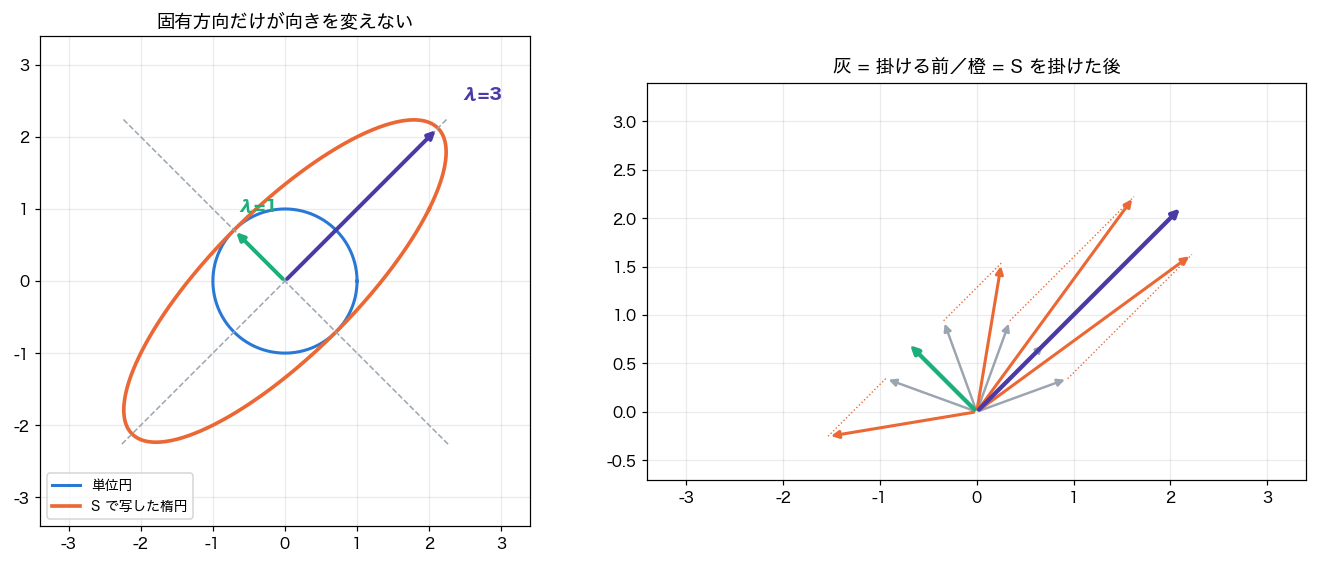

λ=1  v=[-0.7071  0.7071]  S@v=[-0.7071  0.7071]  λ*v=[-0.7071  0.7071]  一致:True
λ=3  v=[0.7071 0.7071]  S@v=[2.1213 2.1213]  λ*v=[2.1213 2.1213]  一致:True


In [7]:
S = np.array([[2., 1.], [1., 2.]])
vals, vecs = np.linalg.eigh(S)              # 実対称行列には eigh を使う

th = np.linspace(0, 2*np.pi, 400)
unit = np.vstack([np.cos(th), np.sin(th)])  # 単位円上の点（2 x 400）
img = S @ unit

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.6, 5.2))

#左: 単位円 → 楕円、固有方向は伸びるだけ
a1.plot(unit[0], unit[1], color=BLUE, lw=2, label="単位円")
a1.plot(img[0], img[1], color=ORANGE, lw=2.4, label="S で写した楕円")
for k, c in zip(range(2), [AQUA, VIOLET]):
    v = vecs[:, k]
    a1.plot([-3.2*v[0], 3.2*v[0]], [-3.2*v[1], 3.2*v[1]],
            ls="--", lw=1.0, color="#9aa5b1")
    a1.annotate("", xy=vals[k]*v, xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", lw=2.6, color=c))
    a1.text(vals[k]*v[0]*1.10 + 0.12, vals[k]*v[1]*1.10 + 0.18, f"λ={vals[k]:.0f}",
            color=c, fontweight="bold", fontsize=11)
a1.set_aspect("equal"); a1.set_xlim(-3.4, 3.4); a1.set_ylim(-3.4, 3.4)
a1.set_title("固有方向だけが向きを変えない"); a1.legend(loc="lower left", fontsize=9)

#右: 固有方向でない矢印は向きが変わる
for ang in np.deg2rad([20, 70, 110, 160]):
    v = np.array([np.cos(ang), np.sin(ang)]); w = S @ v
    a2.annotate("", xy=v, xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#9aa5b1"))
    a2.annotate("", xy=w, xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", lw=2.0, color=ORANGE))
    a2.plot([v[0], w[0]], [v[1], w[1]], ls=":", lw=0.9, color=ORANGE)
for k, c in zip(range(2), [AQUA, VIOLET]):
    v = vecs[:, k]
    a2.annotate("", xy=v, xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#9aa5b1"))
    a2.annotate("", xy=vals[k]*v, xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", lw=2.8, color=c))
a2.set_aspect("equal"); a2.set_xlim(-3.4, 3.4); a2.set_ylim(-0.7, 3.4)
a2.set_title("灰 = 掛ける前／橙 = S を掛けた後", fontsize=12)
fig.tight_layout(); plt.show()

for k in range(2):
    v = vecs[:, k]
    print(f"λ={vals[k]:.0f}  v={np.round(v,4)}  S@v={np.round(S@v,4)}  "
          f"λ*v={np.round(vals[k]*v,4)}  一致:{np.allclose(S@v, vals[k]*v)}")

| 書き方 | していること | 読みどころ |
| --- | --- | --- |
| `np.linalg.eigh(S)` | 実対称行列の固有値分解 | 固有値は**小さい順**に、固有ベクトルは `vecs[:, k]`（列）に入る。一般の正方行列には `eig` を使うが、対称と分かっているなら `eigh` のほうが速く、必ず実数を返す |
| `vecs[:, k]` | 第 k 固有ベクトル | `vecs[k]` は**第 k 行**であって固有ベクトルではない。最も多い取り違え |
| `S @ unit` | 単位円を一括で写す | `unit` は $2\times400$。行列積 1 回で 400 点すべてを変換している |
| `np.allclose(S@v, vals[k]*v)` | 定義式そのもので検算 | 「戻り値が 2 つ」と覚えるのではなく、$Ax=\lambda x$ に代入して確かめる |

この正定値行列の例では、楕円の半長軸の長さが最大固有値、半短軸の長さが最小固有値に対応している。
これは第 13 回の主成分分析で「データの広がりが最大の方向」を探す操作とそのまま重なる。

---
## 5. 正規直交基底と直交行列（教科書 0.6）

### 5.1 Gram–Schmidt の正体は「射影を引く」

$v_1,\dots,v_n$ から正規直交基底 $u_1,\dots,u_n$ を作る手順は次の 2 式に尽きる。

$$u_j' = v_j-\sum_{k<j}\langle v_j,u_k\rangle\,u_k,\qquad u_j=\frac{u_j'}{\|u_j'\|}$$

第 1 式で<u><font color="#E8710A">すでに確保した方向の成分をすべて抜き取り</font></u>、第 2 式で長さを 1 にそろえる。
$\langle v_j,u_k\rangle$ は<u><font color="#E8710A">1 個の数</font></u>であって、それを $u_k$ に掛けたものが射影ベクトルである。
「成分を引く」は各座標から同じ数を引くことではない。

$u_j'=0$ になるのは $v_j$ が既存の方向の一次結合で書けてしまう場合、つまり一次従属のときである。
だから割る前に長さを調べる処理が必要になる。

---

**<font color="#C08A00">［命題］命題 7・命題 8（教科書 p.11）</font>**

**命題 7**　$P$ が直交行列（$P^TP=I$）$\iff$ $P$ の列が正規直交基底をなす。
このとき $P^{T}=P^{-1}$ であり $\langle Pu,Pv\rangle=u^TP^TPv=\langle u,v\rangle$、
すなわち**直交変換は内積（したがって長さと角度）を変えない**。

**命題 8**　対称行列では、異なる固有値に属する固有ベクトルは直交する。

---

命題 8 の証明は一行である。$Ax=\lambda x,\ Ay=\mu y,\ \lambda\neq\mu$ のとき
$\lambda x^Ty=(Ax)^Ty=x^TA^Ty=x^TAy=\mu x^Ty$ なので $(\lambda-\mu)x^Ty=0$、よって $x^Ty=0$。

In [8]:
def gram_schmidt(A):
    """A の列に Gram-Schmidt を適用し、正規直交な列をもつ Q を返す"""
    Q = np.zeros_like(A, dtype=float)
    for j in range(A.shape[1]):
        u = A[:, j].copy()                       # copy しないと A を壊す
        for k in range(j):
            u = u - (Q[:, k] @ u) * Q[:, k]      # 内積（スカラー）× 方向ベクトル
        length = np.linalg.norm(u)
        if length < 1e-12:
            raise ValueError(f"第{j}列は既存の列の一次結合（一次従属）")
        Q[:, j] = u / length
    return Q

A = np.array([[1., 1.], [1., 0.], [0., 1.]])     # v1=(1,1,0), v2=(1,0,1)
Q = gram_schmidt(A)
R = Q.T @ A

print("Q =\n", np.round(Q, 6))
print("Q^T Q = I :", np.allclose(Q.T @ Q, np.eye(2)))
print("Q R = A   :", np.allclose(Q @ R, A), " ← 基底を取り替えただけで情報は落ちていない")
print("R =\n", np.round(R, 6), " ← 上三角になる")

Q2, R2 = np.linalg.qr(A)                          # ライブラリの QR 分解
print("\nnp.linalg.qr との列ごとの比較（符号は反転しうる）:")
for j in range(2):
    print(f"  第{j}列  同符号={np.allclose(Q[:,j], Q2[:,j])}  "
          f"逆符号={np.allclose(Q[:,j], -Q2[:,j])}")

Q =
 [[ 0.707107  0.408248]
 [ 0.707107 -0.408248]
 [ 0.        0.816497]]
Q^T Q = I : True
Q R = A   : True  ← 基底を取り替えただけで情報は落ちていない
R =
 [[1.414214 0.707107]
 [0.       1.224745]]  ← 上三角になる

np.linalg.qr との列ごとの比較（符号は反転しうる）:
  第0列  同符号=False  逆符号=True
  第1列  同符号=True  逆符号=False


---

**<font color="#D93025">［注意］符号が逆でも間違いではない</font>**

$Q$ の第 $j$ 列の符号を反転し、同時に $R$ の第 $j$ 行の符号も反転すれば積 $QR$ は変わらない。
実装を比較するときは「値が一致するか」ではなく
**「$QR=A$ と $Q^TQ=I$ という 2 つの等式を満たすか」**で判定する。
紙の Gram–Schmidt は構造の理解に有効だが、有限桁の計算では丸め誤差が蓄積するので、
実務では `np.linalg.qr`（Householder 変換に基づく）を使う。

---

---
## 6. 対称行列の対角化と非負定値性（教科書 0.7）

### 6.1 命題 9 — 対称行列は必ず直交行列で対角化できる

---

**<font color="#C08A00">［命題］命題 9（教科書 p.12）</font>**

対称行列 $A$ は、適当な直交行列 $P$ を用いて $P^{-1}AP$ をすべての固有値を対角成分とする
対角行列にすることができる。すなわち $A=P\Lambda P^{T}$、
$\Lambda=\mathrm{diag}(\lambda_1,\dots,\lambda_n)$。

---

実対称行列には実固有値と単位固有ベクトル $u$ が存在する。$u$ の直交補空間も $A$ で不変である。
実際、$u^Tv=0$ なら $u^TAv=(Au)^Tv=\lambda u^Tv=0$ となる。
その補空間に制限した実対称行列にも同じ議論を繰り返すと、正規直交な固有ベクトルの基底が得られる。
実用上は<u><font color="#E8710A">$A$ を掛ける操作は、直交基底に座標を取り替えてから各軸を $\lambda_i$ 倍するだけ</font></u>と読むとよい。

### 6.2 命題 10 — 非負定値の 3 条件

---

**<font color="#C08A00">［命題］命題 10（教科書 p.12）</font>**

大きさ $n$ の対称行列 $A$ について、以下の 3 条件は同値である。

1. $A=B^{T}B$ となる行列 $B\in\mathbb{R}^{m\times n}$ が存在する
2. 任意の $x\in\mathbb{R}^n$ について $x^{T}Ax\ge0$
3. $A$ のすべての固有値が非負

これを満たす $A$ を**非負定値**、固有値がすべて正のものを**正定値**とよぶ。

---

3 つの向きの証明はどれも短い。

1. $1\Rightarrow2$：$x^TAx=x^TB^TBx=\|Bx\|^2\ge0$。

2. $2\Rightarrow3$：固有ベクトル $x$（$\|x\|=1$）を代入すると $x^TAx=\lambda\|x\|^2=\lambda\ge0$。

3. $3\Rightarrow1$：命題 9 より $A=P\Lambda P^T$。$\lambda_i\ge0$ なので $\sqrt{\Lambda}$ が作れて $A=(\sqrt{\Lambda}P^T)^T(\sqrt{\Lambda}P^T)$。

$1\Rightarrow2$ の一行が、この講義全体でいちばん使う。
$X^TX$ は $B=X$ とおいた形なので<u><font color="#E8710A">$X^TX$ は常に非負定値</font></u>。だから第 6 回で
$X^TX+N\lambda I$ の固有値は $\mu_i+N\lambda>0$ となり、$\lambda>0$ である限り必ず正則になる。

### 6.3 二次形式の等高線で 3 つの型を見る

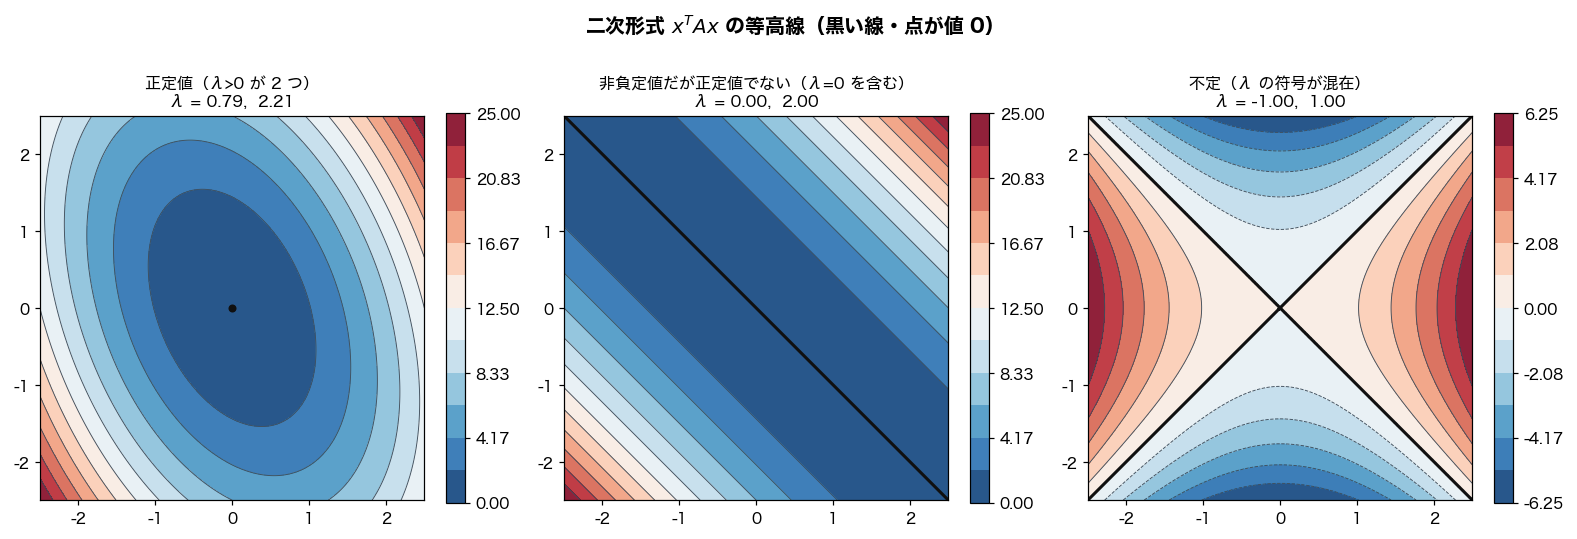

正定値（λ>0 が 2 つ）                         固有値 [0.793 2.207]   x^T A x の最小値  0.000
非負定値だが正定値でない（λ=0 を含む）                  固有値 [0. 2.]   x^T A x の最小値  0.000
不定（λ の符号が混在）                           固有値 [-1.  1.]   x^T A x の最小値 -10.053


In [9]:
mats = [
    (np.array([[2., 0.5], [0.5, 1.]]), "正定値（λ>0 が 2 つ）"),
    (np.array([[1., 1.], [1., 1.]]),   "非負定値だが正定値でない（λ=0 を含む）"),
    (np.array([[1., 0.], [0., -1.]]),  "不定（λ の符号が混在）"),
]
u = np.linspace(-2.5, 2.5, 200)
U, V = np.meshgrid(u, u)

fig, axes = plt.subplots(1, 3, figsize=(14.4, 4.7))
for ax, (A, title) in zip(axes, mats):
    Z = A[0, 0]*U**2 + 2*A[0, 1]*U*V + A[1, 1]*V**2      # x^T A x
    lv = np.linspace(Z.min(), Z.max(), 13)
    cs = ax.contourf(U, V, Z, levels=lv, cmap="RdBu_r", alpha=0.9)
    ax.contour(U, V, Z, levels=lv, colors="#41505e", linewidths=0.6)
    #非負定値の例では、最小値0の等高線をcontourだけでは描けないため明示する
    w, directions = np.linalg.eigh(A)
    if np.all(w > 1e-12):
        ax.scatter([0], [0], color="#101010", s=18, zorder=4)  #正定値: 零集合は原点
    elif np.all(w >= -1e-12):
        direction = directions[:, np.argmin(np.abs(w))]
        extent = 2.5 / np.max(np.abs(direction))
        t = np.linspace(-extent, extent, 200)
        ax.plot(t * direction[0], t * direction[1], color="#101010", lw=2.0)
    else:
        ax.contour(U, V, Z, levels=[0.0], colors=["#101010"], linewidths=2.0)
    ax.set_title(f"{title}\nλ = {w[0]:.2f},  {w[1]:.2f}", fontsize=10.5)
    ax.set_aspect("equal"); ax.grid(False)
    fig.colorbar(cs, ax=ax, fraction=0.046)
fig.suptitle("二次形式 $x^{T}Ax$ の等高線（黒い線・点が値 0）", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.90]); plt.show()

xs = np.random.default_rng(1).standard_normal((2000, 2))
for A, title in mats:
    w = np.linalg.eigvalsh(A)
    q = np.einsum("ij,jk,ik->i", xs, A, xs)              # 各行について x^T A x
    print(f"{title:38s} 固有値 {np.round(w,3)}   x^T A x の最小値 {q.min(): .3f}")

| 書き方 | していること | 読みどころ |
| --- | --- | --- |
| `np.meshgrid(u, u)` | 格子点を作る | `U` と `V` はどちらも $200\times200$。`U[i,j]` が $x$ 座標、`V[i,j]` が $y$ 座標 |
| `A[0,0]*U**2 + 2*A[0,1]*U*V + A[1,1]*V**2` | $x^TAx$ の成分表示 | 対称行列なので交差項は $2a_{12}xy$ の 1 つにまとまる |
| `contourf` / `contour` | 塗りと等高線 | 値の正負を表すので発散配色（RdBu）を使う。中央の白が 0 |
| `np.einsum("ij,jk,ik->i", xs, A, xs)` | 2000 点まとめて二次形式 | for 文を使わずに各行 $x_i$ について $x_i^TAx_i$ を計算する |
| `np.linalg.eigvalsh` | 対称行列の固有値だけ | 固有ベクトルが不要なときはこちらが速い |

---

**<font color="#E8710A">［要点］3 枚の図が意味するもの</font>**

**左（正定値）**はすり鉢状で、最小値は原点ただ 1 点。第 2 回の二乗誤差
$L=\|y-X\beta\|^2$ が一意の最小解をもつのは $X^TX$ が正定値のときである。

**中央（非負定値だが正定値でない）**は谷底が**直線**になっている。最小値はあるが、
それを与える $\beta$ は一意でない。$X$ の 2 列が等しい場合がこれ。

**右（不定）**は鞍点で、最小値が存在しない。

第 6 回の Ridge は、中央の状態に $N\lambda\|\beta\|^2$（すり鉢）を足して
強制的に左の状態へ持ち込む操作である。

---

---
## 7. 補足 — 特異値分解は長方形への一般化

固有値分解は正方行列にしか使えない。$N\times p$ の計画行列を扱う機械学習では
<u><font color="#E8710A">特異値分解（SVD）</font></u> $X=U\Sigma V^{T}$ のほうが自然な場面が多い。
$U\in\mathbb{R}^{N\times N}$、$V\in\mathbb{R}^{p\times p}$ は直交行列、
$\Sigma\in\mathbb{R}^{N\times p}$ は非負の対角成分（特異値）をもつ。

以下のコードは`full_matrices=False`の縮約形を使う。$k=\min(N,p)$ とすると、
$U$ は $N\times k$、$\Sigma$ は $k\times k$、$V^T$ は $k\times p$ となる。

$X^TX=V\Sigma^{T}\Sigma V^{T}$ なので、<u><font color="#E8710A">$X$ の特異値の二乗が $X^TX$ の固有値</font></u>になる。
中心化したデータでは、分母を $N$ とする定義の共分散行列は $X^TX/N$ だから、第 13 回の主成分分析は
「$X$ の SVD を取る」ことと同じ計算になる。

$\Sigma^{+}$ を「非零の特異値を逆数にし、零の方向は零のまま」とした行列とすると、
$X^{+}=V\Sigma^{+}U^{T}$ が擬似逆行列で、これが <code>np.linalg.lstsq</code> の返す
<u><font color="#E8710A">ノルム最小の最小二乗解</font></u>を与える。

In [10]:
rg = np.random.default_rng(3)
X = rg.standard_normal((6, 3))
X[:, 2] = X[:, 0] + X[:, 1]                 # 第3列を従属にする → rank = 2
U, s, Vt = np.linalg.svd(X, full_matrices=False)

print("特異値 s       =", np.round(s, 6))
print("s^2            =", np.round(s**2, 6))
print("X^T X の固有値 =", np.round(np.sort(np.linalg.eigvalsh(X.T @ X))[::-1], 6))
print("rank(X)        =", np.linalg.matrix_rank(X), "← 0 でない特異値の個数")
print("X = U S V^T の復元 :", np.allclose(U @ np.diag(s) @ Vt, X))

y = rg.standard_normal(6)
beta_ls, *_ = np.linalg.lstsq(X, y, rcond=None)
s_plus = np.array([1/si if si > 1e-10 else 0.0 for si in s])   # 擬似逆を自作
beta_pinv = Vt.T @ np.diag(s_plus) @ U.T @ y

print("\nlstsq の解   :", np.round(beta_ls, 6))
print("擬似逆の解   :", np.round(beta_pinv, 6))
print("残差が等しい :", np.allclose(X @ beta_ls, X @ beta_pinv))
print("ノルム       :", round(float(np.linalg.norm(beta_ls)), 6),
      "（同じ残差を与える解の中で最小）")

特異値 s       = [5.996935 3.358485 0.      ]
s^2            = [35.963234 11.279422  0.      ]
X^T X の固有値 = [35.963234 11.279422 -0.      ]
rank(X)        = 2 ← 0 でない特異値の個数
X = U S V^T の復元 : True

lstsq の解   : [ 0.280433 -0.232975  0.047458]
擬似逆の解   : [ 0.280433 -0.232975  0.047458]
残差が等しい : True
ノルム       : 0.367658 （同じ残差を与える解の中で最小）


---
## 8. 演習

教科書の第 0 章には章末問題がないため、第 2 回以降で実際に必要になる形の問題を用意した。
まず自分で解いてから、下の解答セルを実行して照合すること。

---

**<font color="#7B3FB5">［演習］演習 1（階数と正則性）</font>**

$X\in\mathbb{R}^{N\times(p+1)}$ の第 0 列がすべて 1 であるとする。

(a) $N<p+1$ のとき $X^TX$ が逆行列をもたないことを、命題 1 と命題 3 を使って示せ。

(b) $X$ のある 2 列が等しいときも同様であることを示せ。

(c) $\operatorname{rank}(X^TX)=\operatorname{rank}(X)$ を示せ。

ヒント：$X^TXz=0\Rightarrow z^TX^TXz=\|Xz\|^2=0\Rightarrow Xz=0$

---

---

**<font color="#7B3FB5">［演習］演習 2（Gram–Schmidt と検算）</font>**

$v_1=(1,1,0)^T,\ v_2=(1,0,1)^T,\ v_3=(2,1,1)^T$ に `gram_schmidt` を適用すると
どうなるか、実行する前に予想せよ。予想した理由も書くこと。

---

---

**<font color="#7B3FB5">［演習］演習 3（非負定値性）</font>**

$A=\begin{bmatrix}2&1\\1&2\end{bmatrix}$、$\lambda\ge0$ とする。

(a) $A+\lambda I$ の固有値を $\lambda$ の式で表せ。

(b) $\lambda>0$ ならば $A+\lambda I$ は必ず正則であることを示せ。

(c) $A$ を「2 列が等しい行列の $X^TX$」に取り替えても (b) が成り立つ理由を述べよ。

---

In [11]:
#解答と確認用の実装（まず自分で解いてから実行すること）
print("=== 演習1 ===")
rg = np.random.default_rng(7)
N, p = 3, 5
X = np.hstack([np.ones((N, 1)), rg.standard_normal((N, p))])      # N < p+1
print(f"(a) X:{X.shape}  rank(X)={np.linalg.matrix_rank(X)}  "
      f"rank(X^T X)={np.linalg.matrix_rank(X.T@X)} < {p+1} → 命題1より正則でない")

X2 = rg.standard_normal((10, 4)); X2[:, 3] = X2[:, 1]             # 2列が等しい
print(f"(b) X2:{X2.shape} rank={np.linalg.matrix_rank(X2)} < 4  "
      f"det(X2^T X2) = {np.linalg.det(X2.T@X2):.3e} ≈ 0")

X3 = rg.standard_normal((20, 6))
print(f"(c) rank(X3)={np.linalg.matrix_rank(X3)}  "
      f"rank(X3^T X3)={np.linalg.matrix_rank(X3.T@X3)} で一致")

print("\n=== 演習2 ===")
V = np.array([[1., 1., 2.], [1., 0., 1.], [0., 1., 1.]])
print("v3 = v1 + v2 :", np.allclose(V[:, 2], V[:, 0] + V[:, 1]))
try:
    gram_schmidt(V)
except ValueError as e:
    print("→ 例外:", e)
print("rank =", np.linalg.matrix_rank(V), "（3列あっても独立な方向は 2 本）")

print("\n=== 演習3 ===")
A = np.array([[2., 1.], [1., 2.]])
base = np.linalg.eigvalsh(A)
print("A の固有値 :", np.round(base, 4), "→ 1 と 3")
for lam in [0.0, 0.1, 1.0, 5.0]:
    w = np.linalg.eigvalsh(A + lam*np.eye(2))
    print(f"  λ={lam:<4} 固有値={np.round(w,4)}  "
          f"det={np.linalg.det(A + lam*np.eye(2)):.4f}")

Xd = np.array([[1., 1.], [2., 2.], [3., 3.]])      # 2列が等しい
G = Xd.T @ Xd
print("\n2列が等しい X^T X の固有値 :", np.round(np.linalg.eigvalsh(G), 6),
      "→ 0 を含むので正則でない")
for lam in [0.0, 0.5, 2.0]:
    print(f"  +{lam}I の固有値 :", np.round(np.linalg.eigvalsh(G + lam*np.eye(2)), 6),
          f"  det={np.linalg.det(G + lam*np.eye(2)):.4f}")

=== 演習1 ===
(a) X:(3, 6)  rank(X)=3  rank(X^T X)=3 < 6 → 命題1より正則でない
(b) X2:(10, 4) rank=3 < 4  det(X2^T X2) = 0.000e+00 ≈ 0
(c) rank(X3)=6  rank(X3^T X3)=6 で一致

=== 演習2 ===
v3 = v1 + v2 : True
→ 例外: 第2列は既存の列の一次結合（一次従属）
rank = 2 （3列あっても独立な方向は 2 本）

=== 演習3 ===
A の固有値 : [1. 3.] → 1 と 3
  λ=0.0  固有値=[1. 3.]  det=3.0000
  λ=0.1  固有値=[1.1 3.1]  det=3.4100
  λ=1.0  固有値=[2. 4.]  det=8.0000
  λ=5.0  固有値=[6. 8.]  det=48.0000

2列が等しい X^T X の固有値 : [ 0. 28.] → 0 を含むので正則でない
  +0.0I の固有値 : [ 0. 28.]   det=0.0000
  +0.5I の固有値 : [ 0.5 28.5]   det=14.2500
  +2.0I の固有値 : [ 2. 30.]   det=60.0000


---
## 9. この回のまとめ

| 教科書の事実 | 式 | 後で使う場面 |
| --- | --- | --- |
| 命題 1 | $A$ 正則 $\iff \operatorname{rank}(A)=n \iff \det(A)\neq0$ | 第 2 回：$(X^TX)^{-1}$ の存在条件 |
| 命題 2 | $\det(AB)=\det(A)\det(B)$ | 第 4 回：Sherman–Morrison–Woodbury の証明 |
| 命題 3 | $\operatorname{rank}(AB)\le\min\{\operatorname{rank}(A),\operatorname{rank}(B)\}$ | 第 2 回：$N<p+1$ で $X^TX$ が非正則 |
| 命題 4 | $\dim(\text{像})+\dim(\text{核})=n$ | 第 2 回：ハット行列 $H$ の固有値 0 と 1 の重複度 |
| 命題 5・6 | $\det(A-\lambda I)=0$、固有空間は部分空間 | 第 13 回：主成分の方向 |
| 命題 7・8 | $P^TP=I$、対称行列の固有ベクトルは直交 | 第 2 回：$RSS/\sigma^2\sim\chi^2_{N-p-1}$ の導出 |
| 命題 9 | $A=P\Lambda P^{T}$ | 第 6 回：Ridge の固有値による説明／第 13 回：PCA |
| 命題 10 | $A\succeq0\iff A=B^TB\iff x^TAx\ge0\iff \lambda_i\ge0$ | 第 6 回：$X^TX+N\lambda I\succ0$ |

---

**<font color="#E8710A">［要点］3 つの習慣</font>**

1. **形を確かめる**：計算の前後で `.shape` を印字する。エラーの大半はここで防げる。
2. **列の意味を言葉にする**：「この列は何の特徴量か」「この行は何件目か」を口に出す。
3. **元の式に代入して検算する**：`np.allclose` の左右がどの数式なのかを毎回説明できるようにする。

---

次回は、これらを使って $\hat\beta=(X^TX)^{-1}X^Ty$ を導出し、
その分布・仮説検定・信頼区間まで一気に進めましょう！！

## 参考資料とこのNotebookの範囲

鈴木讓 著『統計的機械学習の数理100問 with Python』共立出版、2020年。ISBN: 9784320125070。
[出版社の書籍紹介](https://www.kyoritsu-pub.co.jp/book/b10003244.html)

第0章の線形代数を中心とした学習記録です。SVD・擬似逆行列や図による説明も含みます。
「第2回」「第6回」などはNotebook内の学習計画上の参照であり、他の回の実装完了を示すものではありません。
数値例での一致確認と一般的な命題の証明は区別します。掲載時の補足・修正はREADMEに記載しています。

実対称行列の対角化と一般の実行列の三角化は条件が異なります。
参考：[SciPyのSchur分解の説明](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.schur.html)。
縮約SVDの形状は[NumPy公式ドキュメント](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)を参照してください。
